0.8165178492839196
0.24990280802148895
0.24609876581126014
0.2372159081431807
0.20793216413350174
0.12311905720649353
0.07888166506355147
0.07655073683421636
0.07637803086238222
0.0761876413118557


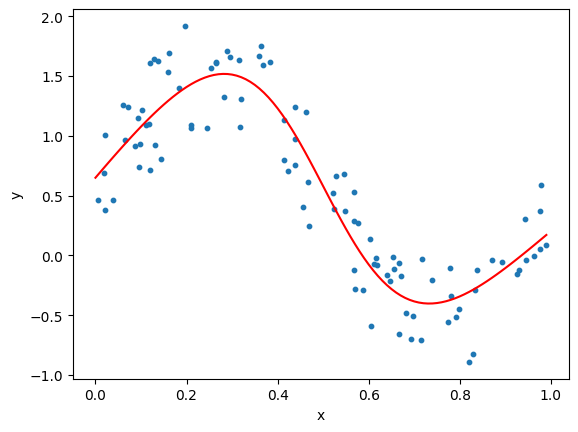

In [5]:
# Basic Code

import numpy as np
import matplotlib.pyplot as plt
from dezero import Model
from dezero import optimizers  # 옵티마이저들이 들어 있는 패키지 임포트
import dezero.layers as L
import dezero.functions as F

# 데이터셋 생성
np.random.seed(0)
x = np.random.rand(100, 1)
y = np.sin(2 * np.pi * x) + np.random.rand(100, 1)

lr = 0.2
iters = 10000

class TwoLayerNet(Model):
    def __init__(self, hidden_size, out_size):
        super().__init__()
        self.l1 = L.Linear(hidden_size)
        self.l2 = L.Linear(out_size)

    def forward(self, x):
        y = F.sigmoid(self.l1(x))
        y = self.l2(y)
        return y

model = TwoLayerNet(10, 1)
optimizer = optimizers.SGD(lr)  # 옵티마이저 생성
optimizer.setup(model)          # 최적화할 모델을 옵티마이저에 등록

for i in range(iters):
    y_pred = model(x)
    loss = F.mean_squared_error(y, y_pred)

    model.cleargrads()
    loss.backward()

    optimizer.update()  # 옵티마이저로 매개변수 갱신
    if i % 1000 == 0:
        print(loss.data)

# 그래프로 시각화([그림 7-12]와 같음)
plt.scatter(x, y, s=10)
plt.xlabel('x')
plt.ylabel('y')
t = np.arange(0, 1, .01)[:, np.newaxis]
y_pred = model(t)
plt.plot(t, y_pred.data, color='r')
plt.show()

0.8708413001916949
0.5432727975020838
0.5431590414428323
0.5430340359798312
0.5428918693138196
0.5427266984711889
0.5425331051989989
0.542306481964844
0.5420432356244305
0.5417407233201519


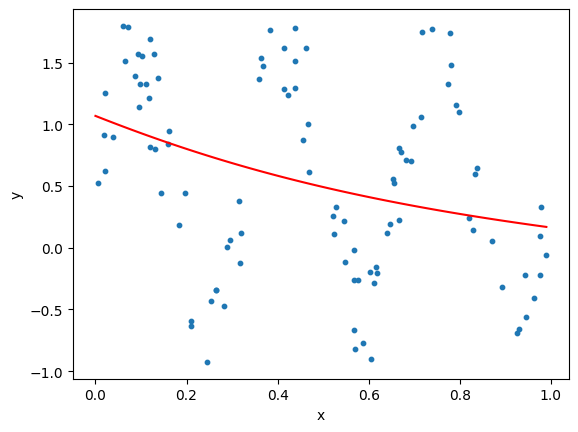

In [6]:
# sin(6 * np.pi * x)

import numpy as np
import matplotlib.pyplot as plt
from dezero import Model
from dezero import optimizers  # 옵티마이저들이 들어 있는 패키지 임포트
import dezero.layers as L
import dezero.functions as F

# 데이터셋 생성
np.random.seed(0)
x = np.random.rand(100, 1)
y = np.sin(6 * np.pi * x) + np.random.rand(100, 1)

lr = 0.2
iters = 10000

class TwoLayerNet(Model):
    def __init__(self, hidden_size, out_size):
        super().__init__()
        self.l1 = L.Linear(hidden_size)
        self.l2 = L.Linear(out_size)

    def forward(self, x):
        y = F.sigmoid(self.l1(x))
        y = self.l2(y)
        return y

model = TwoLayerNet(10, 1)
optimizer = optimizers.SGD(lr)  # 옵티마이저 생성
optimizer.setup(model)          # 최적화할 모델을 옵티마이저에 등록

for i in range(iters):
    y_pred = model(x)
    loss = F.mean_squared_error(y, y_pred)

    model.cleargrads()
    loss.backward()

    optimizer.update()  # 옵티마이저로 매개변수 갱신
    if i % 1000 == 0:
        print(loss.data)

# 그래프로 시각화([그림 7-12]와 같음)
plt.scatter(x, y, s=10)
plt.xlabel('x')
plt.ylabel('y')
t = np.arange(0, 1, .01)[:, np.newaxis]
y_pred = model(t)
plt.plot(t, y_pred.data, color='r')
plt.show()

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from dezero import no_grad, optimizers
from dezero.models import MLP
import dezero.functions as F

# 학습 데이터: 100개 고정
rng = np.random.RandomState(0)
x = rng.rand(100, 1)
y = np.sin(6 * np.pi * x)

# 평가용 데이터: 학습에 사용하지 않음
t = np.linspace(0, 1, 1000).reshape(-1, 1)
y_true = np.sin(6 * np.pi * t)


def train_case(name, hidden=(50, 50), activation=F.tanh,
               optimizer_name="Adam", lr=0.01,
               init_method="xavier", iters=10000, seed=0):

    np.random.seed(seed)

    # 모델 생성
    model = MLP((*hidden, 1), activation=activation)

    # 가중치 초기 생성
    with no_grad():
        model(x[:1])

    # 가중치 초기화 방식 선택
    if init_method != "default":
        np.random.seed(seed)

        for layer in model.layers:
            W = layer.W.data
            fan_in, fan_out = W.shape

            if init_method == "xavier":
                std = np.sqrt(2.0 / (fan_in + fan_out))
            elif init_method == "he":
                std = np.sqrt(2.0 / fan_in)
            else:
                raise ValueError("Unknown initialization")

            layer.W.data = (
                np.random.randn(*W.shape) * std
            ).astype(W.dtype)

    # Optimizer 선택
    if optimizer_name == "SGD":
        optimizer = optimizers.SGD(lr)
    elif optimizer_name == "MomentumSGD":
        optimizer = optimizers.MomentumSGD(lr)
    elif optimizer_name == "Adam":
        optimizer = optimizers.Adam(alpha=lr)
    else:
        raise ValueError("Unknown optimizer")

    optimizer.setup(model)

    # 학습
    losses = []

    for i in range(iters):
        y_pred = model(x)
        loss = F.mean_squared_error(y, y_pred)

        model.cleargrads()
        loss.backward()
        optimizer.update()

        losses.append(float(loss.data))

    # 평가
    with no_grad():
        pred = model(t).data.copy()
        train_pred = model(x).data.copy()

    train_mse = float(np.mean((y - train_pred) ** 2))
    grid_mse = float(np.mean((y_true - pred) ** 2))

    print(
        f"{name}: Train MSE={train_mse:.6f}, "
        f"Grid MSE={grid_mse:.6f}"
    )

    return {
        "name": name,
        "pred": pred,
        "losses": losses,
        "train_mse": train_mse,
        "grid_mse": grid_mse
    }


def plot_three(results, title):
    # 그래프 1: 회귀 결과
    plt.figure(figsize=(8, 5))
    plt.scatter(x, y, s=12, color="gray", label="Training data")
    plt.plot(t, y_true, "k--", label="Target")

    for r in results:
        plt.plot(t, r["pred"], label=r["name"])

    plt.title(f"{title} - Regression")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 그래프 2: Loss 변화
    plt.figure(figsize=(8, 5))

    for r in results:
        plt.plot(r["losses"], label=r["name"])

    plt.title(f"{title} - Training Loss")
    plt.xlabel("Iteration")
    plt.ylabel("MSE Loss")
    plt.yscale("log")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 그래프 3: 최종 MSE
    positions = np.arange(len(results))
    width = 0.35

    plt.figure(figsize=(8, 5))
    plt.bar(
        positions - width / 2,
        [r["train_mse"] for r in results],
        width,
        label="Train MSE"
    )
    plt.bar(
        positions + width / 2,
        [r["grid_mse"] for r in results],
        width,
        label="Grid MSE"
    )

    plt.xticks(positions, [r["name"] for r in results])
    plt.title(f"{title} - Final MSE")
    plt.ylabel("MSE")
    plt.legend()
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()

2L-50N: Train MSE=0.000007, Grid MSE=0.000014
2L-10N: Train MSE=0.000007, Grid MSE=0.000014
2L-100N: Train MSE=0.000711, Grid MSE=0.000748
1L-50N: Train MSE=0.036162, Grid MSE=0.061265
3L-50N: Train MSE=0.000018, Grid MSE=0.000082


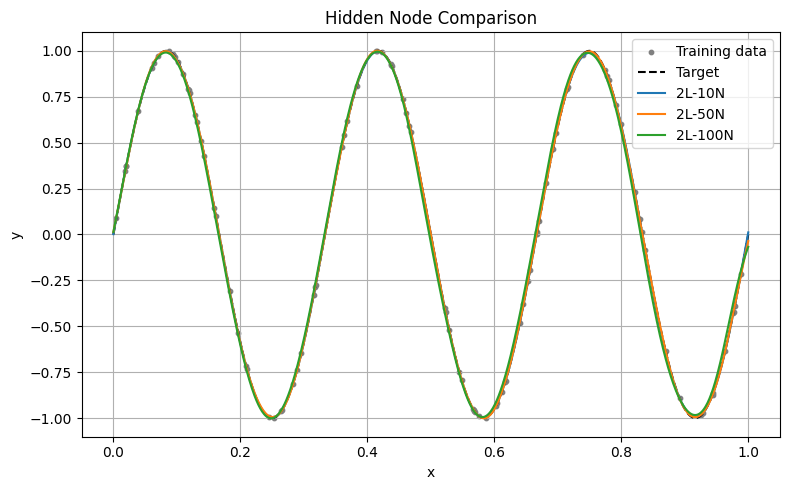

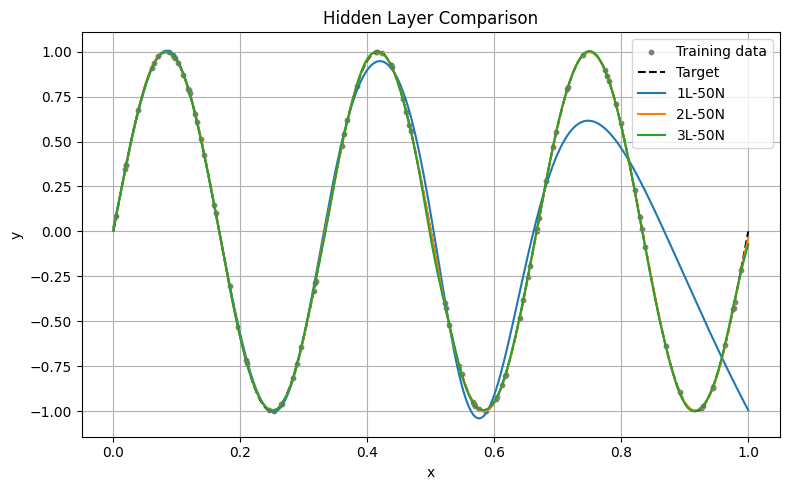

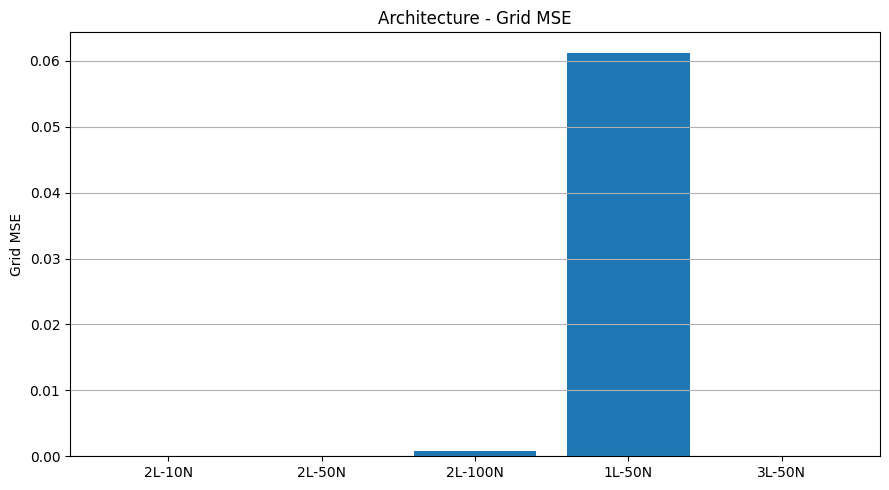

In [8]:
# Hidden Layer, Node 수
# 기준 모델: 은닉층 2개, 노드 50개씩
base = train_case("2L-50N", hidden=(50, 50))

# 노드 수 비교
node_results = [
    train_case("2L-10N", hidden=(10, 10)),
    base,
    train_case("2L-100N", hidden=(100, 100))
]

# 은닉층 수 비교
layer_results = [
    train_case("1L-50N", hidden=(50,)),
    base,
    train_case("3L-50N", hidden=(50, 50, 50))
]

# 그래프 1: 노드 수에 따른 회귀 결과
plt.figure(figsize=(8, 5))
plt.scatter(x, y, s=10, color="gray", label="Training data")
plt.plot(t, y_true, "k--", label="Target")

for r in node_results:
    plt.plot(t, r["pred"], label=r["name"])

plt.title("Hidden Node Comparison")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 그래프 2: 은닉층 수에 따른 회귀 결과
plt.figure(figsize=(8, 5))
plt.scatter(x, y, s=10, color="gray", label="Training data")
plt.plot(t, y_true, "k--", label="Target")

for r in layer_results:
    plt.plot(t, r["pred"], label=r["name"])

plt.title("Hidden Layer Comparison")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 그래프 3: 전체 모델의 Grid MSE 비교
all_results = [
    node_results[0],
    base,
    node_results[2],
    layer_results[0],
    layer_results[2]
]

plt.figure(figsize=(9, 5))
plt.bar(
    [r["name"] for r in all_results],
    [r["grid_mse"] for r in all_results]
)
plt.title("Architecture - Grid MSE")
plt.ylabel("Grid MSE")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

SGD: Train MSE=0.451072, Grid MSE=0.470262
MomentumSGD: Train MSE=0.029304, Grid MSE=0.049521
Adam: Train MSE=0.000007, Grid MSE=0.000014


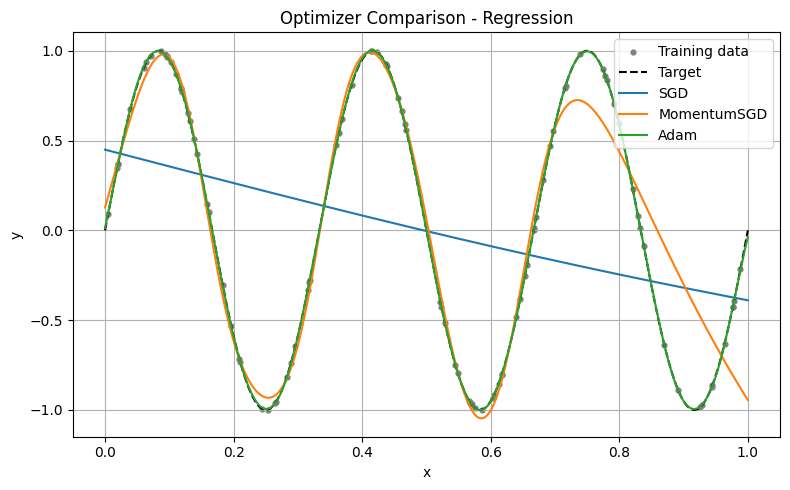

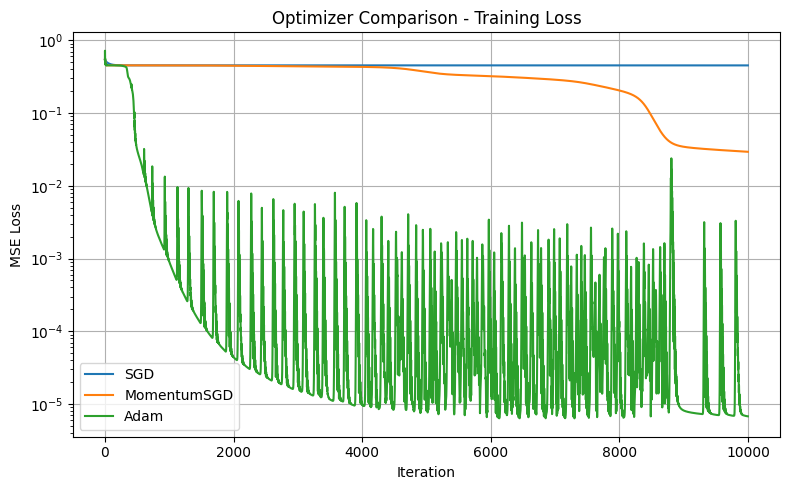

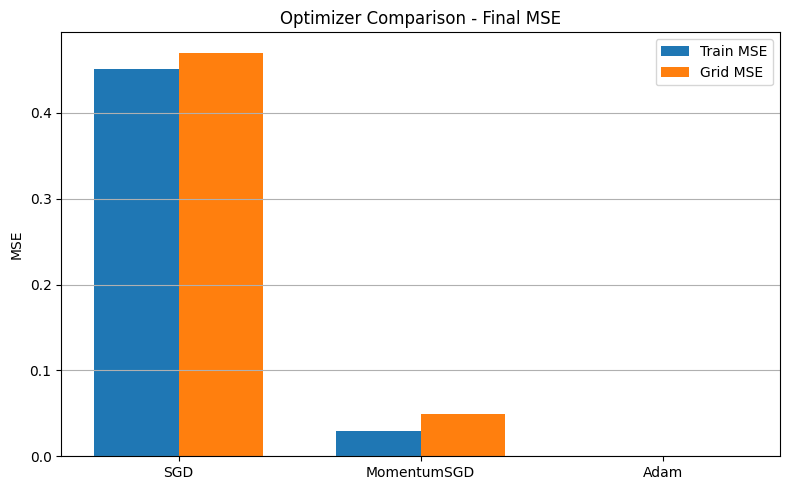

In [9]:
# 2. Optimizer 비교
results = [
    train_case("SGD", optimizer_name="SGD"),
    train_case("MomentumSGD", optimizer_name="MomentumSGD"),
    train_case("Adam", optimizer_name="Adam")
]

plot_three(results, "Optimizer Comparison")

Sigmoid: Train MSE=0.000051, Grid MSE=0.000098
Tanh: Train MSE=0.000007, Grid MSE=0.000014
ReLU: Train MSE=0.039232, Grid MSE=0.065983


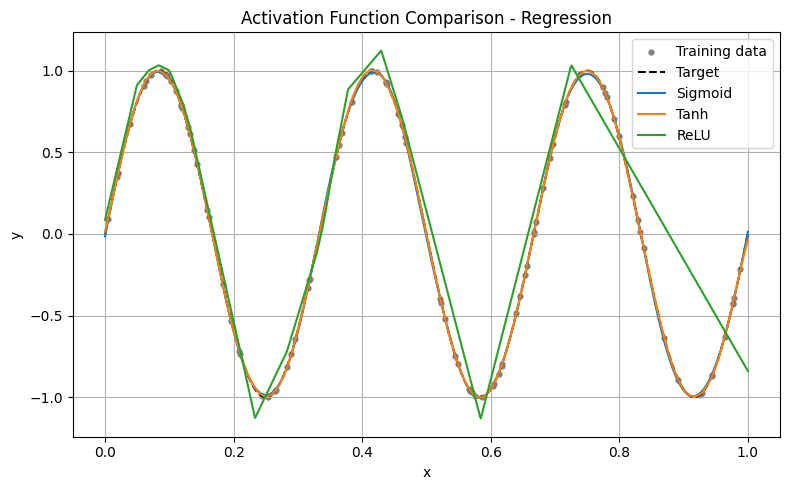

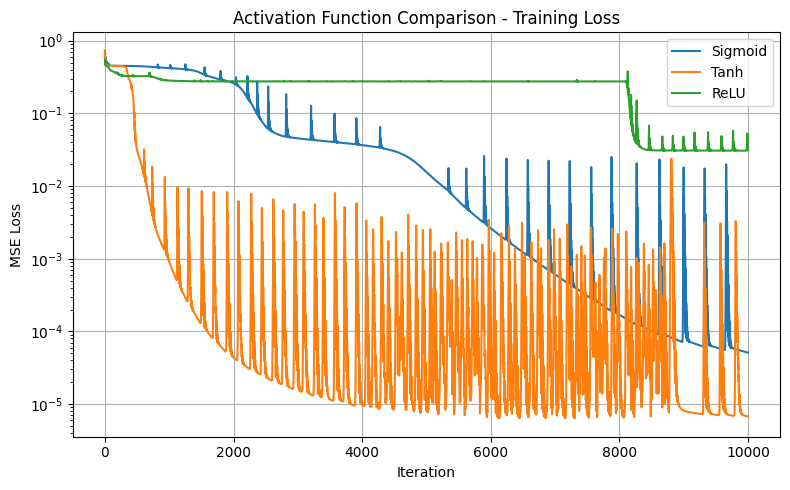

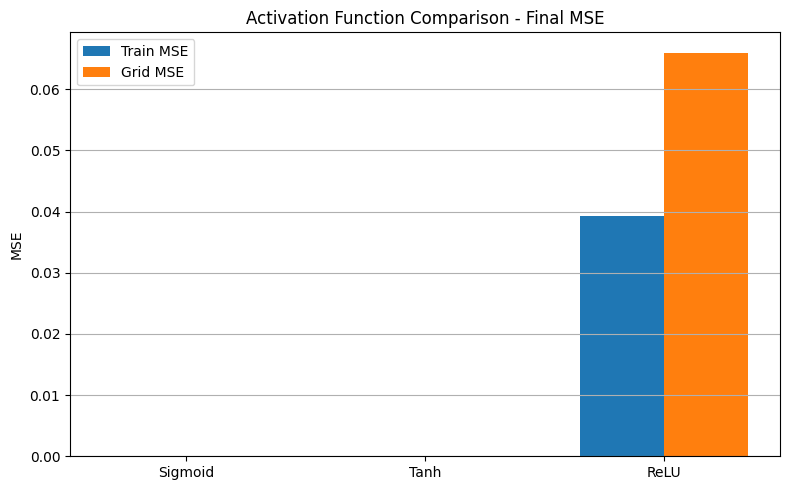

In [10]:
# 3. Activation Fuction
results = [
    train_case("Sigmoid", activation=F.sigmoid),
    train_case("Tanh", activation=F.tanh),
    train_case("ReLU", activation=F.relu)
]

plot_three(results, "Activation Function Comparison")

Default: Train MSE=0.000009, Grid MSE=0.000021
Xavier: Train MSE=0.000007, Grid MSE=0.000014
He: Train MSE=0.000625, Grid MSE=0.000743


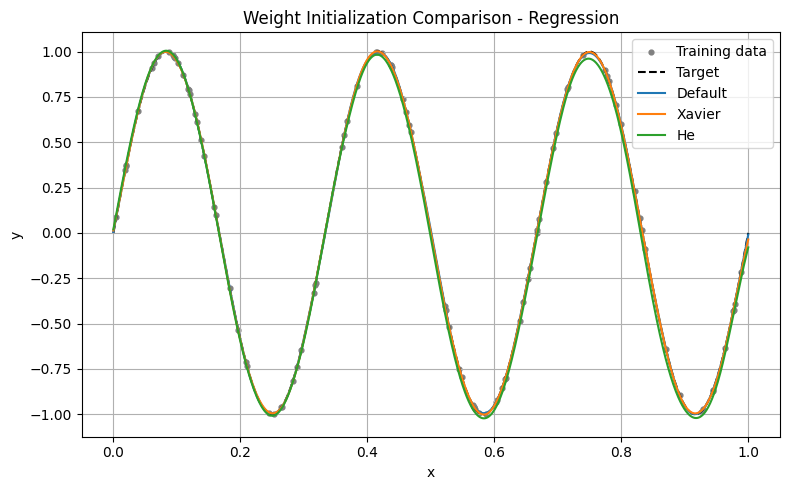

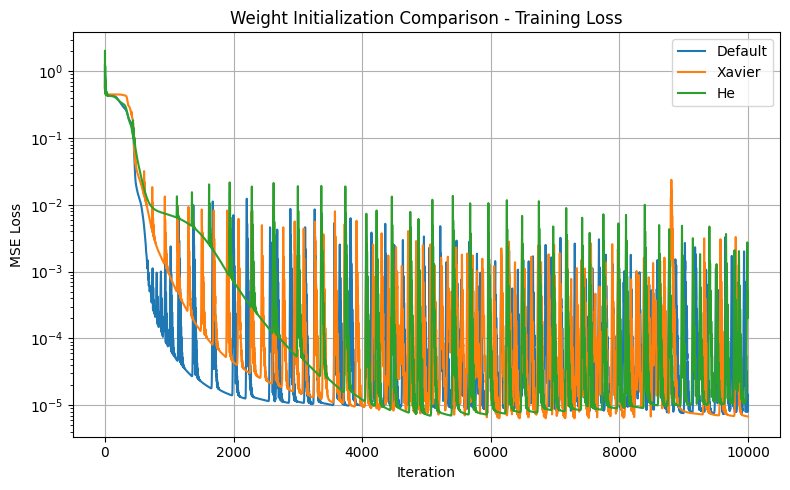

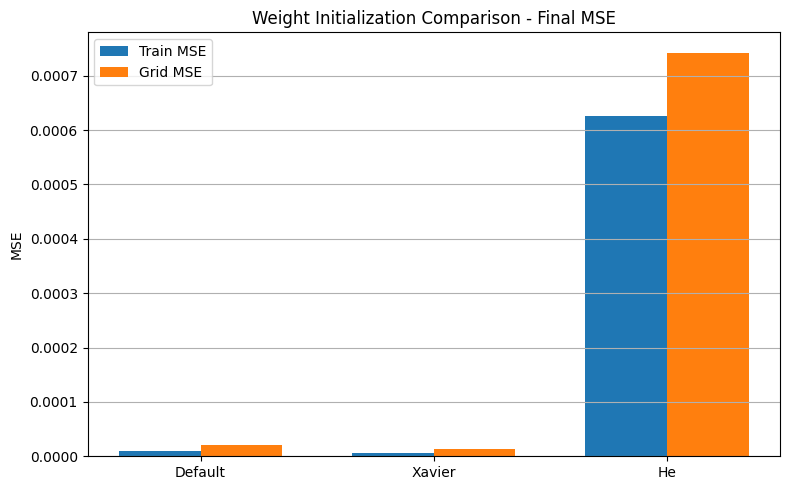

In [11]:
# 4. Weight Initialization
results = [
    train_case("Default", init_method="default"),
    train_case("Xavier", init_method="xavier"),
    train_case("He", init_method="he")
]

plot_three(results, "Weight Initialization Comparison")

LR=0.001: Train MSE=0.000008, Grid MSE=0.000018
LR=0.01: Train MSE=0.000007, Grid MSE=0.000014
LR=0.05: Train MSE=0.372872, Grid MSE=0.403557


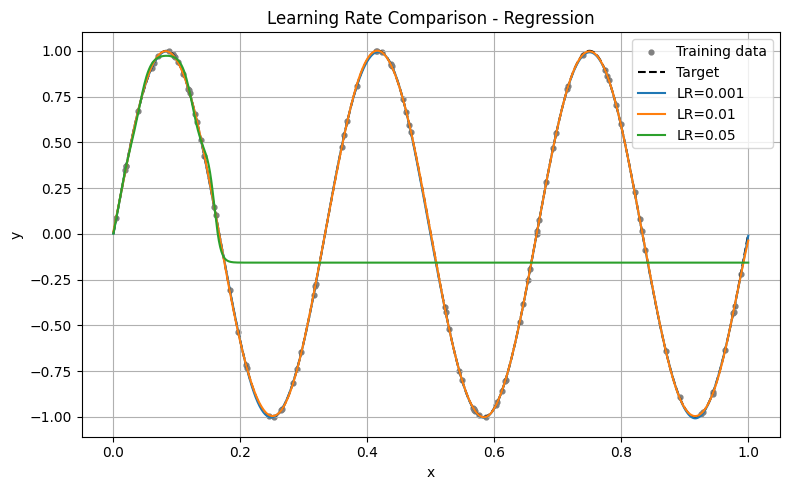

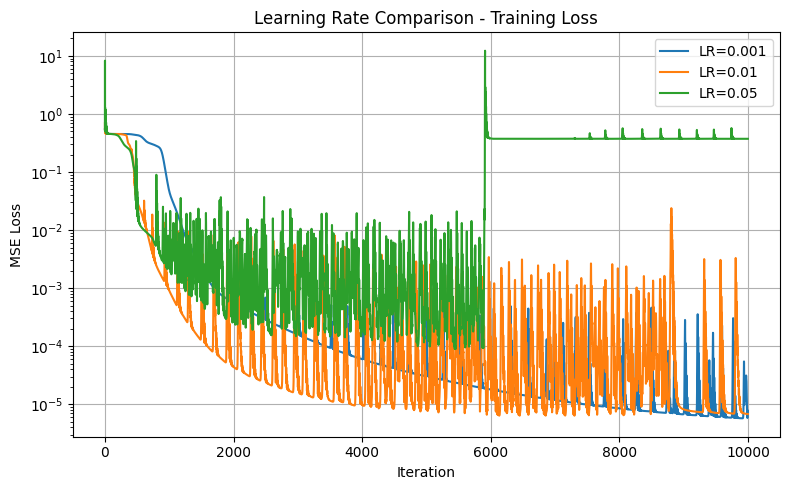

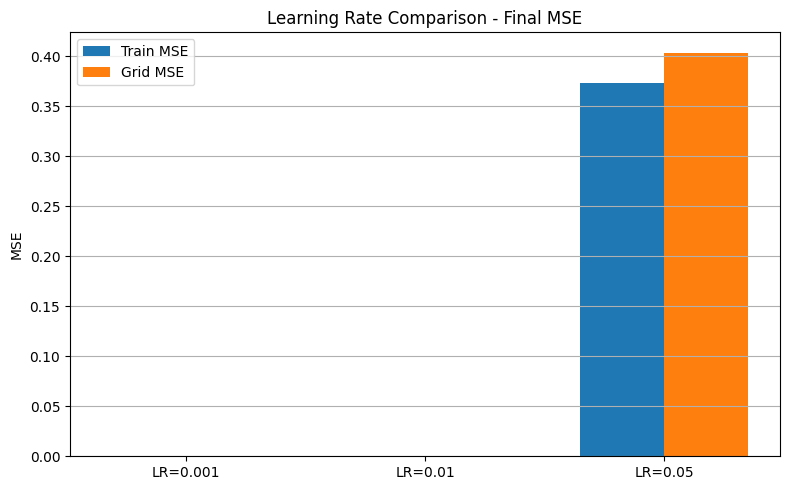

In [12]:
# 5. 기타 Parameter - Learning Rate
results = [
    train_case("LR=0.001", lr=0.001),
    train_case("LR=0.01", lr=0.01),
    train_case("LR=0.05", lr=0.05)
]

plot_three(results, "Learning Rate Comparison")